In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np
import pyarrow.parquet as pq

import duckdb

## Dataset Inspection

In [63]:
def inspect_parquet_file(path):
    '''Inspect a Parquet file and print its metadata, schema, and a sample of the data.'''
    path = Path(path)

    # Read file metadata only
    metadata = pq.read_metadata(path)

    print("Rows:", metadata.num_rows)
    print("Columns:", metadata.num_columns)

    # Inspect the columns and their data types
    schema = pq.read_schema(path)

    for field in schema:
        print(field.name, field.type)

    # Examine the first few rows of the dataset
    con = duckdb.connect()

    df_sample = con.execute(
        '''
        SELECT *
        FROM read_parquet(?)
        USING SAMPLE 10 ROWS;
        ''',
        [str(path)]
    ).df()

    display(df_sample)

In [64]:
inspect_parquet_file("/home/georgiusbenedikt09/MLOps_Credit_Risk/dataset/raw/train/train_base.parquet")

Rows: 1526659
Columns: 5
case_id int64
date_decision string
MONTH int64
WEEK_NUM int64
target int64


,case_id,date_decision,MONTH,WEEK_NUM,target
0,2036,2019-01-21,201901,2,0
1,3324,2019-01-31,201901,4,0
2,6544,2019-02-28,201902,8,0
3,15079,2019-05-17,201905,19,1
4,20478,2019-06-26,201906,25,0
5,24321,2019-07-26,201907,29,0
6,1650565,2019-11-26,201911,47,0
7,1651712,2019-11-27,201911,47,0
8,1652978,2019-11-29,201911,47,0
9,1655463,2019-11-29,201911,47,0


In [78]:
inspect_parquet_file("/home/georgiusbenedikt09/MLOps_Credit_Risk/dataset/raw/train/train_credit_bureau_a_2_0.parquet")

Rows: 5296031
Columns: 19
case_id int64
collater_typofvalofguarant_298M string
collater_typofvalofguarant_407M string
collater_valueofguarantee_1124L double
collater_valueofguarantee_876L double
collaterals_typeofguarante_359M string
collaterals_typeofguarante_669M string
num_group1 int64
num_group2 int64
pmts_dpd_1073P double
pmts_dpd_303P double
pmts_month_158T double
pmts_month_706T double
pmts_overdue_1140A double
pmts_overdue_1152A double
pmts_year_1139T double
pmts_year_507T double
subjectroles_name_541M string
subjectroles_name_838M string


,case_id,collater_typofvalofguarant_298M,collater_typofvalofguarant_407M,collater_valueofguarantee_1124L,collater_valueofguarantee_876L,collaterals_typeofguarante_359M,collaterals_typeofguarante_669M,num_group1,num_group2,pmts_dpd_1073P,pmts_dpd_303P,pmts_month_158T,pmts_month_706T,pmts_overdue_1140A,pmts_overdue_1152A,pmts_year_1139T,pmts_year_507T,subjectroles_name_541M,subjectroles_name_838M
0,614243,a55475b1,a55475b1,NaN,NaN,a55475b1,a55475b1,1,17,NaN,NaN,7.0,NaN,NaN,NaN,2018.0,NaN,a55475b1,a55475b1
1,1269233,a55475b1,a55475b1,NaN,NaN,a55475b1,a55475b1,0,19,NaN,NaN,9.0,NaN,NaN,NaN,2019.0,NaN,a55475b1,a55475b1
2,1269500,a55475b1,a55475b1,NaN,NaN,a55475b1,a55475b1,0,10,0.0,NaN,12.0,NaN,0.0,NaN,2017.0,NaN,a55475b1,a55475b1
3,1269562,a55475b1,a55475b1,NaN,NaN,a55475b1,a55475b1,0,29,NaN,NaN,7.0,NaN,NaN,NaN,2019.0,NaN,a55475b1,a55475b1
4,1269587,a55475b1,a55475b1,NaN,NaN,a55475b1,a55475b1,1,33,NaN,NaN,11.0,NaN,NaN,NaN,2019.0,NaN,a55475b1,a55475b1
5,1269610,9a0c095e,a55475b1,0.0,NaN,a55475b1,c7a5ad39,1,0,NaN,NaN,2.0,NaN,NaN,NaN,2017.0,NaN,a55475b1,ab3c25cf
6,1269652,a55475b1,a55475b1,NaN,NaN,a55475b1,a55475b1,0,1,0.0,NaN,3.0,NaN,0.0,NaN,2017.0,NaN,a55475b1,a55475b1
7,1288964,a55475b1,a55475b1,NaN,NaN,a55475b1,a55475b1,0,7,0.0,NaN,9.0,NaN,0.0,NaN,2017.0,NaN,a55475b1,a55475b1
8,1289062,a55475b1,a55475b1,NaN,NaN,a55475b1,a55475b1,0,21,0.0,NaN,11.0,NaN,0.0,NaN,2018.0,NaN,a55475b1,a55475b1
9,1289120,a55475b1,a55475b1,NaN,NaN,a55475b1,a55475b1,0,1,NaN,NaN,3.0,NaN,NaN,NaN,2017.0,NaN,a55475b1,a55475b1


In [69]:
inspect_parquet_file("/home/georgiusbenedikt09/MLOps_Credit_Risk/dataset/raw/train/train_applprev_2.parquet")

Rows: 14075487
Columns: 6
case_id int64
cacccardblochreas_147M string
conts_type_509L string
credacc_cards_status_52L string
num_group1 int64
num_group2 int64


,case_id,cacccardblochreas_147M,conts_type_509L,credacc_cards_status_52L,num_group1,num_group2
0,52,None,PRIMARY_MOBILE,None,2,0
1,175,None,PRIMARY_MOBILE,None,0,0
2,4873,None,EMPLOYMENT_PHONE,None,1,2
3,6320,None,PRIMARY_MOBILE,None,3,0
4,18608,None,EMPLOYMENT_PHONE,None,0,1
5,19239,None,PRIMARY_MOBILE,None,1,1
6,20324,None,EMPLOYMENT_PHONE,None,18,0
7,22190,None,EMPLOYMENT_PHONE,None,1,1
8,23590,None,PRIMARY_MOBILE,None,8,0
9,24454,None,EMPLOYMENT_PHONE,None,4,0


In [86]:
df_sample = con.execute(
    '''
    SELECT *
    FROM read_parquet(?)
    USING SAMPLE 10 ROWS;
    ''',
    ["/home/georgiusbenedikt09/MLOps_Credit_Risk/dataset/raw/train/train_tax_registry_a_1.parquet"]
).df()

display(df_sample)

,case_id,amount_4527230A,name_4527232M,num_group1,recorddate_4527225D
0,923931,165.0,5e180ef0,5,2020-01-16
1,925783,3345.0,12f60f45,2,2020-01-18
2,927159,1000.0,bdce75e2,9,2020-01-18
3,927623,1598.0,e4758d1e,2,2020-01-19
4,928109,4226.2,4819aabf,5,2020-01-19
5,928241,1100.0,ecdeb790,0,2020-01-19
6,1660940,5008.2,3abf826d,5,2019-12-14
7,1660995,683.2,e177ab10,5,2019-12-14
8,1661392,233.8,5f9b74f5,10,2019-12-14
9,2648564,1567.6,2db524b2,5,2019-12-22


## EDA

In [ ]:
# Unique case_id counts and null values in the train_base.parquet file
con = duckdb.connect()

path = "/home/georgiusbenedikt09/MLOps_Credit_Risk/dataset/raw/train/train_base.parquet"

df_sample = con.execute(
    '''
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT case_id) AS unique_case_ids,
        COUNT(*) - COUNT(case_id) AS null_case_ids
    FROM read_parquet(?)
    ''',
    [str(path)]
).df()

display(df_sample)

,total_rows,unique_case_ids,null_case_ids
0,1526659,1526659,0


<Axes: xlabel='WEEK_NUM', ylabel='Default rate (%)'>

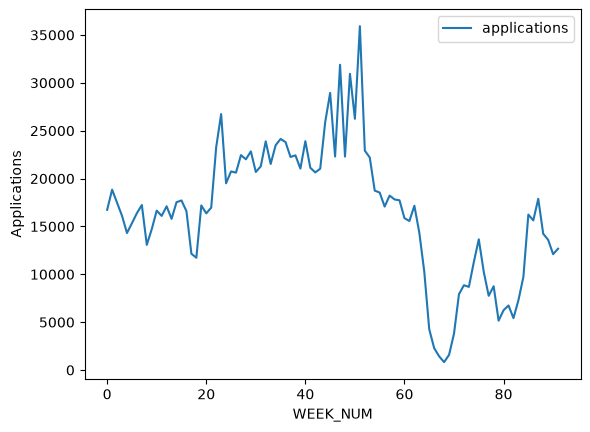

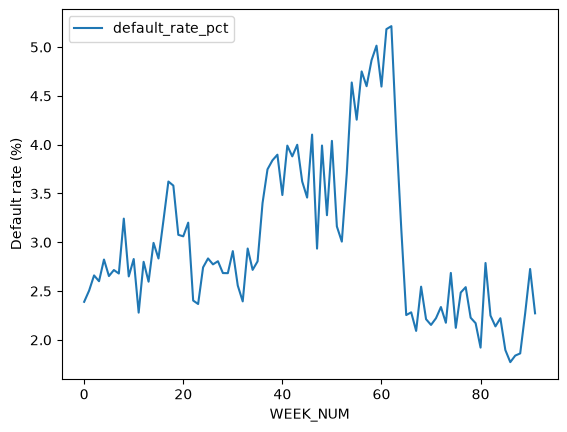

In [ ]:
# Weekly applications and default rates
path = "/home/georgiusbenedikt09/MLOps_Credit_Risk/dataset/raw/train/train_base.parquet"

weekly = con.execute(
    """
    SELECT
        WEEK_NUM,
        COUNT(*) AS applications,
        COUNT_IF(target = 1) AS defaults,
        100.0 * AVG(target) AS default_rate_pct
    FROM read_parquet(?)
    GROUP BY WEEK_NUM
    ORDER BY WEEK_NUM
    """,
    [str(path)],
).df()

weekly.plot(x="WEEK_NUM", y="applications", ylabel="Applications")
weekly.plot(x="WEEK_NUM", y="default_rate_pct", ylabel="Default rate (%)")

In [57]:
# Analyze the join between train_base.parquet and other feature files
    # Analyzing cardinality and coverage of feature files when joined with the base dataset.
path = "/home/georgiusbenedikt09/MLOps_Credit_Risk/dataset/raw/train/train_base.parquet"
train_dir = Path(path).parent
base_path = path

def inspect_join(feature_glob):
    return con.execute(
        """
        WITH feature_counts AS (
            SELECT
                case_id,
                COUNT(*) AS records
            FROM read_parquet(?)
            WHERE case_id IS NOT NULL
            GROUP BY case_id
        )
        SELECT
            COUNT(*) AS base_cases,
            COUNT(f.case_id) AS matched_cases,
            ROUND(100.0 * COUNT(f.case_id) / COUNT(*), 2) AS coverage_pct,
            COUNT_IF(f.case_id IS NULL) AS unmatched_cases,
            COUNT_IF(f.records = 1) AS cases_with_one_match,
            COUNT_IF(f.records > 1) AS cases_with_multiple_matches,
            MAX(f.records) AS max_records_per_case,
            (SELECT COUNT(*) FROM feature_counts WHERE records > 1) AS duplicate_feature_case_ids
        FROM read_parquet(?) AS b
        LEFT JOIN feature_counts AS f
        ON b.case_id = f.case_id
        """,
        [str(train_dir / feature_glob), str(base_path)],
    ).df()

# display(inspect_join("train_applprev_1_*.parquet"))
# display(inspect_join("train_applprev_2.parquet"))
# display(inspect_join("train_credit_bureau_a_1_*.parquet"))
# display(inspect_join("train_credit_bureau_a_2_*.parquet"))
# display(inspect_join("train_credit_bureau_b_1.parquet"))
# display(inspect_join("train_credit_bureau_b_2.parquet"))
# display(inspect_join("train_debitcard_*.parquet"))
# display(inspect_join("train_deposit_*.parquet"))
# display(inspect_join("train_other_*.parquet"))
# display(inspect_join("train_person_1.parquet"))
# display(inspect_join("train_person_2.parquet"))
display(inspect_join("train_static_0_*.parquet"))
display(inspect_join("train_static_cb_*.parquet"))
display(inspect_join("train_tax_registry_a_*.parquet"))
display(inspect_join("train_tax_registry_b_*.parquet"))
display(inspect_join("train_tax_registry_c_*.parquet"))

,base_cases,matched_cases,coverage_pct,unmatched_cases,cases_with_one_match,cases_with_multiple_matches,max_records_per_case,duplicate_feature_case_ids
0,1526659,1526659,100.0,0.0,1526659.0,0.0,1,0


,base_cases,matched_cases,coverage_pct,unmatched_cases,cases_with_one_match,cases_with_multiple_matches,max_records_per_case,duplicate_feature_case_ids
0,1526659,1500476,98.28,26183.0,1500476.0,0.0,1,0


,base_cases,matched_cases,coverage_pct,unmatched_cases,cases_with_one_match,cases_with_multiple_matches,max_records_per_case,duplicate_feature_case_ids
0,1526659,457934,30.0,1068725.0,16518.0,441416.0,99,441416


,base_cases,matched_cases,coverage_pct,unmatched_cases,cases_with_one_match,cases_with_multiple_matches,max_records_per_case,duplicate_feature_case_ids
0,1526659,150732,9.87,1375927.0,1522.0,149210.0,101,149210


,base_cases,matched_cases,coverage_pct,unmatched_cases,cases_with_one_match,cases_with_multiple_matches,max_records_per_case,duplicate_feature_case_ids
0,1526659,482265,31.59,1044394.0,19089.0,463176.0,121,463176
